# Estado del arte: el motor de referencia ORE, QuantLib y lo que queda fuera de línea

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 02 y 06 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué ofrecen el Open Source Risk Engine (ORE) y QuantLib para la exposición de contraparte, y qué no ofrece ninguno;
- leer una conciliación de un perfil de exposición contra ORE en errores estándar combinados de Monte Carlo, y calcularla desde los arreglos versionados;
- decir en cuáles de las seis variantes del caso C12 el motor coincide con ORE, en cuáles no, y qué dice el documento sobre las causas;
- leer la comparación de las formas cerradas de Hull-White del motor con las de QuantLib, y el triángulo forma cerrada, simulación y ORE;
- decir qué queda fuera de línea en el producto, y por qué.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw
from riskvalidation.validation import ccr as vc

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son las seis variantes del caso C12 (riesgo de crédito de contraparte): el swap único, el conjunto de neteo de cuatro swaps, el CSA con 10 y con 20 días hábiles, el CSA con margen inicial, y la variante de correlación adversa. Las operaciones son convenciones sintéticas, la curva es la curva a la par del Tesoro de EE. UU. del 2025-09-30 (clase de licencia `mirror-allowed`). Cada documento tiene el bloque `ore_reconciliation`: el perfil que ORE 1.8.17.0 produjo para las mismas operaciones y curva (10.000 muestras antitéticas, corrido de forma nativa con la rueda de Python, no en este cuaderno), la coincidencia punto a punto y el estado.

- **Archivos que se leen:** los seis documentos bajo `data/derived/C12/`, claves `outputs.exposure`, `outputs.ore_reconciliation`, `outputs.initial_margin` y `tests`. ORE no está instalado ni se corre aquí: es una rueda nativa de 77,6 MB que queda fuera de línea, y sus archivos de configuración están bajo control de versiones en el pipeline como evidencia de lo que se corrió (`data-pipeline/pipeline/cases/c12/ore_inputs/`).
- **Estado de verdad:** `synthetic-calibrated`. Lo que muestra una conciliación es la coincidencia entre dos implementaciones del mismo modelo sobre las mismas entradas, no que el modelo sea correcto (el cuaderno 06 muestra que no lo es).

La celda siguiente carga los seis documentos e imprime el estado de cada conciliación.

In [2]:
# Cargar las seis variantes versionadas de C12 (el cuaderno está tres carpetas bajo la raíz del repositorio) e imprimir el estado de cada conciliación con ORE
ROOT = Path("../../..").resolve()
names = ["single-swap", "netting-set", "csa-mpor-10d", "csa-mpor-20d", "with-im", "wrong-way-risk"]
docs = {n: json.loads((ROOT / "data" / "derived" / "C12" / f"{n}.json").read_text(encoding="utf-8")) for n in names}

print("calculado con riskvalidation", docs["single-swap"]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print(f"{'variante':16s}{'estado':16s}{'todo dentro de 2 ee':>20s}{'corrida de ORE, s':>18s}")
for n in names:
    o = docs[n]["outputs"]["ore_reconciliation"]
    print(f"{n:16s}{ {'reconciled': 'conciliada', 'not-applicable': 'no aplica'}.get(o['status'], o['status']):16s}{ {True: 'sí', False: 'no'}.get(o['all_within_two_se'], '-'):>20s}{(round(o['run_seconds'], 1) if o['run_seconds'] else '-'):>18}")
platform = docs["single-swap"]["outputs"]["ore_reconciliation"]
print("versión de ORE:", platform["ore_version"])
print("variante sin conciliación con ORE, y por qué:", docs["wrong-way-risk"]["outputs"]["ore_reconciliation"]["reason"]["es"])

calculado con riskvalidation 0.8.1 | instalado 0.8.1
variante        estado           todo dentro de 2 ee corrida de ORE, s
single-swap     conciliada                        sí              33.2
netting-set     conciliada                        sí              64.7
csa-mpor-10d    conciliada                        no              89.4
csa-mpor-20d    conciliada                        no             126.0
with-im         conciliada                        no             123.1
wrong-way-risk  no aplica                          -                 -
versión de ORE: 1.8.17.0
variante sin conciliación con ORE, y por qué: El ejemplo de riesgo de dirección equivocada de ORE es otro modelo (un LGM de crédito correlacionado), no el hazard de Hull y White (2012) sobre el valor del portafolio, por lo que esta variante no tiene conciliación con ORE.


## Método

### Paso 1: el perfil de EE contra ORE

ORE y el motor dan cada uno una estimación de la misma exposición esperada en 33 fechas, con un error de Monte Carlo. `reconcile_ee_profile`, del motor, toma los dos perfiles con sus errores y devuelve, como estadístico, la mayor brecha en **errores estándar combinados**

$$z_k = \frac{|EE_k - EE^{ORE}_k|}{\sqrt{se_k^2 + se_k^{ORE\,2}}}$$

con un umbral interno de Contraste de 2 para verde (un umbral, no uno regulatorio). Ambos perfiles son la EE sin descontar en medida forward del documento: el perfil descontado de ORE dividido por $P(0,t)$, la misma transformación por la que pasa el perfil del motor. La celda siguiente recalcula el estadístico de las cinco variantes que tienen referencia, desde los arreglos versionados, y lo compara con la fila versionada.

In [3]:
# Recalcular el estadístico de reconcile_ee_profile de cada variante desde los arreglos versionados y compararlo con la fila versionada
checked = [n for n in names if docs[n]["outputs"]["ore_reconciliation"]["status"] != "not-applicable"]
k1 = 11
print(f"{'variante':14s}{'nuestro':>9s}{'versionado':>11s}{'puntos en 2 ee':>16s}{'luz':>7s}{'ORE/Python a 1 a':>18s}{'media (Py-ORE)/ee':>22s}")
z = {}
for n in checked:
    o = docs[n]["outputs"]
    ee, ee_se = np.array(o["exposure"]["ee"]["values"]), np.array(o["exposure"]["ee"]["mc_se"])
    ref, ref_se = np.array(o["ore_reconciliation"]["ore_ee"]["values"]), np.array(o["ore_reconciliation"]["ore_ee"]["mc_se"])
    t = vc.reconcile_ee_profile(ee, ee_se, ref, ref_se, k_se=2.0)
    committed = [row for row in docs[n]["tests"] if row["test_id"] == "ccr.reconcile_ee_profile" and row["segment"] is None][0]
    comb = np.sqrt(ee_se**2 + ref_se**2)
    z[n] = (ee - ref) / comb
    print(f"{n:14s}{t.statistic:9.3f}{committed['statistic']:11.3f}{int(np.sum(np.abs(z[n]) <= 2)):12d} /{ee.size:3d}{t.light.value:>7s}{ref[k1] / ee[k1]:18.4f}{float(z[n].mean()):22.2f}")
row10 = [r for r in docs["csa-mpor-10d"]["tests"] if r["test_id"] == "ccr.reconcile_ee_profile" and r["segment"] is None][0]
print("mayor diferencia de la fila versionada del CSA de 10 días, en errores estándar combinados:", round(row10["statistic"], 3), "|", row10["light"])
mta0 = [r for r in docs["csa-mpor-10d"]["tests"] if r["segment"] == "minimum-transfer-amount-0"][0]
print("fila de diagnóstico, CSA de 10 días con monto mínimo de transferencia cero en ambos motores:", round(mta0["statistic"], 3), mta0["light"])
print("qué dice el documento del monto mínimo de transferencia:", docs["csa-mpor-10d"]["outputs"]["collateral"]["limit"]["es"])

variante        nuestro versionado  puntos en 2 ee    luz  ORE/Python a 1 a     media (Py-ORE)/ee
single-swap       0.775      0.775          33 / 33  green            1.0040                 -0.17
netting-set       0.715      0.715          33 / 33  green            1.0042                 -0.18
csa-mpor-10d      9.931      9.931          17 / 33    red            0.9868                  2.38
csa-mpor-20d      7.086      7.086          21 / 33    red            0.9988                  1.47
with-im          11.739     11.739          32 / 33    red            0.8936                  0.19
mayor diferencia de la fila versionada del CSA de 10 días, en errores estándar combinados: 9.931 | red
fila de diagnóstico, CSA de 10 días con monto mínimo de transferencia cero en ambos motores: 3.637 red
qué dice el documento del monto mínimo de transferencia: No se modelan las cronologías de Andersen, Pykhtin y Sokol. El monto mínimo de transferencia actúa sobre el saldo de la grilla del informe; ORE 

### Paso 2: la EEPE, el CVA y el margen inicial dinámico

La misma comparación se aplica a los números que importan para el capital. El documento registra, para cada variante, la EEPE y el CVA de ambos motores con su error combinado (`eepe_agreement`, `cva_agreement`), y para la variante con margen inicial el perfil del margen inicial dinámico medio del `dim_cube` de ORE contra el del motor. La celda siguiente imprime la diferencia de cada uno en errores estándar combinados, con la luz versionada, y la razón de los dos DIM medios.

In [4]:
# EEPE y CVA del motor y de ORE en errores estándar combinados, con la luz versionada; luego la razón de DIM medios
print(f"{'variante':14s}{'EEPE Py':>10s}{'EEPE ORE':>10s}{'en ee':>8s}{'luz':>7s}{'CVA Py':>10s}{'CVA ORE':>10s}{'en ee':>8s}{'luz':>7s}")
for n in checked:
    o = docs[n]["outputs"]["ore_reconciliation"]
    e, c = o["eepe_agreement"], o["cva_agreement"]
    lights = {r["test_id"]: r["light"] for r in docs[n]["tests"] if r["test_id"] in ("ccr.ore_eepe_agreement", "ccr.ore_cva_agreement")}
    print(f"{n:14s}{e['python']:10.1f}{e['ore']:10.1f}{e['difference'] / e['combined_se']:8.2f}{lights['ccr.ore_eepe_agreement']:>7s}"
          f"{c['python']:10.2f}{c['ore']:10.2f}{c['difference'] / c['combined_se']:8.2f}{lights['ccr.ore_cva_agreement']:>7s}")

im = docs["with-im"]["outputs"]
dim_py = np.array(im["initial_margin"]["dim"]["values"])
dim_ore = np.array(im["ore_reconciliation"]["ore_dim"]["values"])
dim_se = np.sqrt(np.array(im["initial_margin"]["dim"]["mc_se"]) ** 2 + np.array(im["ore_reconciliation"]["ore_dim"]["mc_se"]) ** 2)
ratio = dim_ore / dim_py
dim_row = [r for r in docs["with-im"]["tests"] if r["test_id"] == "ccr.ore_dim_agreement"][0]
print("DIM medio a 1 a, motor y ORE:", round(dim_py[k1], 0), round(dim_ore[k1], 0))
print("razón DIM de ORE / motor: media, mínimo, máximo:", round(float(ratio.mean()), 3), round(float(ratio.min()), 3), round(float(ratio.max()), 3))
print("mayor brecha en errores estándar combinados:", round(float(np.max(np.abs(dim_ore - dim_py) / dim_se)), 1), "| versionado", round(dim_row["statistic"], 1), "|", dim_row["light"])

variante         EEPE Py  EEPE ORE   en ee    luz    CVA Py   CVA ORE   en ee    luz
single-swap      87550.9   87810.5    0.30  green  10337.65  10371.78    0.37  green
netting-set      59954.1   60157.2    0.31  green   9477.77   9510.70    0.40  green
csa-mpor-10d     22777.8   22527.8   -1.55  green    699.53    653.89  -15.89    red
csa-mpor-20d     33183.5   32665.3   -2.20    red   1011.72    973.14   -9.88    red
with-im            212.9     198.0   -0.71  green      7.02      6.69   -1.40  green
DIM medio a 1 a, motor y ORE: 110493.0 104805.0
razón DIM de ORE / motor: media, mínimo, máximo: 0.884 0.692 0.997
mayor brecha en errores estándar combinados: 137.4 | versionado 137.4 | red


### Paso 3: las formas cerradas contra QuantLib, y el triángulo

La opción sobre bono y la swaption de Jamshidian de Hull-White del motor se comparan con QuantLib 1.44 (`HullWhite.discountBondOption` y `JamshidianSwaptionEngine`) al generar el documento, en cuatro filas cuyo umbral es una diferencia relativa de $10^{-6}$; QuantLib no está instalado aquí, así que leemos las filas que el documento versionó, con ambos valores. Luego cerramos el triángulo para el swap único: la EE analítica (que no necesita simulación), la EE simulada del motor y la de ORE, en las fechas de reinicio. Si las tres coinciden dentro de sus errores, tres rutas independientes (una forma cerrada, una simulación en Python y una simulación en un motor C++) dan la misma exposición.

In [5]:
# Leer las cuatro filas de QuantLib, y luego comparar la EE analítica, la EE simulada y la EE de ORE del swap único en las fechas de reinicio
single = docs["single-swap"]["outputs"]
for row in docs["single-swap"]["tests"]:
    if row["test_id"].startswith("ccr.quantlib"):
        x = row["extras"]
        rel = abs(x["engine"] - x["quantlib"]) / abs(x["quantlib"])
        print(f"{row['test_id']:30s} motor {x['engine']:12.6f} | QuantLib {x['quantlib']:12.6f} | diferencia relativa {rel:.1e} | {row['light']}")

tenors = np.array([p["tenor_years"] for p in single["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in single["curve"]["points"]])
a, sigma = single["calibration_used"]["a"], single["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
t0 = single["book"]["trades"][0]
swap = sw.Swap(t0["trade_id"], t0["notional"]["amount"], t0["fixed_rate"], t0["side"] == "payer", t0["start_years"], t0["maturity_years"], t0["fixed_frequency_per_year"])
report = np.array(single["exposure"]["time_grid_years"])
resets = sw.reset_times(swap)
pick = [k for k, t in enumerate(report) if np.min(np.abs(resets - t)) < 1e-9]
analytic = ex.analytic_ee_single_swap(swap, report[pick], a, sigma, p0, forward)
ee, ee_se = np.array(single["exposure"]["ee"]["values"])[pick], np.array(single["exposure"]["ee"]["mc_se"])[pick]
ore_ee, ore_se = np.array(single["ore_reconciliation"]["ore_ee"]["values"])[pick], np.array(single["ore_reconciliation"]["ore_ee"]["mc_se"])[pick]
print("fechas en el triángulo:", len(pick))
print("mayor |simulación - analítica| / ee:", round(float(np.max(np.abs(ee - analytic) / ee_se)), 3))
print("mayor |ORE - analítica| / ee:", round(float(np.max(np.abs(ore_ee - analytic) / ore_se)), 3))
print("mayor |ORE - simulación| / ee combinado:", round(float(np.max(np.abs(ore_ee - ee) / np.sqrt(ee_se**2 + ore_se**2))), 3))

ccr.quantlib_bond_call         motor     0.039287 | QuantLib     0.039287 | diferencia relativa 0.0e+00 | green
ccr.quantlib_bond_put          motor     0.035838 | QuantLib     0.035838 | diferencia relativa 0.0e+00 | green
ccr.quantlib_swaption_payer    motor  7010.256951 | QuantLib  7010.256285 | diferencia relativa 9.5e-08 | green
ccr.quantlib_swaption_receiver motor 11140.502980 | QuantLib 11140.503857 | diferencia relativa 7.9e-08 | green
fechas en el triángulo: 19
mayor |simulación - analítica| / ee: 0.891
mayor |ORE - analítica| / ee: 0.465
mayor |ORE - simulación| / ee combinado: 0.659


La última celda dibuja la lección. A la izquierda, la EE del swap único por las tres rutas: no se distinguen. A la derecha, la diferencia estandarizada entre el motor y ORE para el swap único, el CSA de 10 días y el CSA con margen inicial: dentro de la banda de dos errores estándar para el primero, fuera de ella para los otros dos.

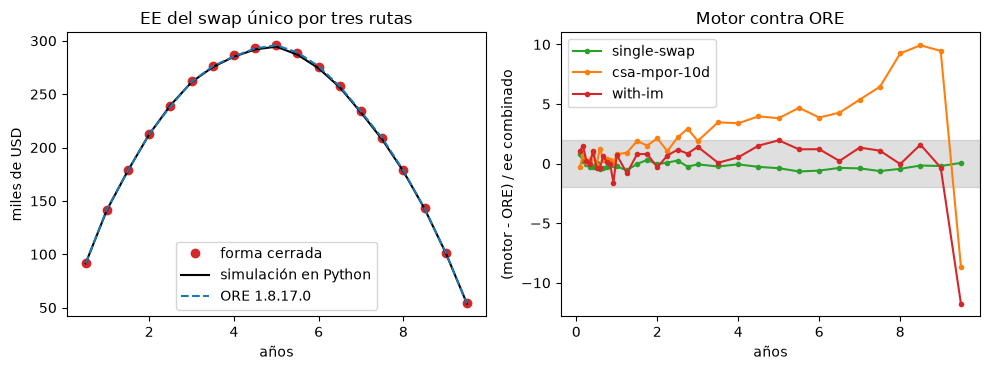

In [6]:
# Dibujar las tres rutas a la EE del swap único (izquierda) y la diferencia estandarizada motor - ORE de tres variantes (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.plot(report[pick], analytic / 1e3, "o", color="tab:red", label="forma cerrada")
left.plot(report[pick], ee / 1e3, "-", color="black", label="simulación en Python")
left.plot(report[pick], ore_ee / 1e3, "--", color="tab:blue", label="ORE 1.8.17.0")
left.set_xlabel("años")
left.set_ylabel("miles de USD")
left.set_title("EE del swap único por tres rutas")
left.legend()
for n, color in (("single-swap", "tab:green"), ("csa-mpor-10d", "tab:orange"), ("with-im", "tab:red")):
    right.plot(np.array(docs[n]["outputs"]["exposure"]["time_grid_years"]), z[n], "o-", ms=3, color=color, label=n)
right.axhspan(-2, 2, color="grey", alpha=0.25)
right.set_xlabel("años")
right.set_ylabel("(motor - ORE) / ee combinado")
right.set_title("Motor contra ORE")
right.legend()
fig.tight_layout()
plt.show()

## Estado del arte

Qué ofrece el mundo de código abierto para la exposición de contraparte, tal como la investigación persistida del caso lo registra desde las fuentes primarias (la metodología y la versión de ORE en la etiqueta 1.8.17.0, el repositorio y el índice de paquetes de QuantLib, el marco de Basilea) y tal como este producto lo usa.

- **ORE (Open Source Risk Engine), 1.8.17.0.** Un motor en C++ con licencia BSD modificada, con una rueda de Python (una rueda nativa de 77,6 MB, Windows, Linux y macOS). Simula la exposición bajo un modelo de tasa de interés Linear Gauss Markov, calcula EE, ENE, PFE y EEPE, CVA, DVA, FVA, MVA y KVA, SA-CCR y BA-CVA, y tiene un margen inicial dinámico por regresión y un módulo ISDA SIMM. Su metodología describe **dos formas de modelar el período de riesgo de margen**: el enfoque preferido de cierre, con una grilla auxiliar desplazada por el MPoR respecto de la grilla de incumplimiento (el que sigue Contraste, con el valor de fecha pegajosa), y un enfoque heredado con rezago. Es la referencia abierta más completa de lo que calcula el caso.
- **QuantLib.** Curvas, instrumentos, motores de valoración y modelos de tasa corta, con opciones sobre bonos de Hull-White en forma cerrada y un motor de swaptions de Jamshidian, contra los que se verifican las formas cerradas del motor. QuantLib **no tiene un flujo empaquetado de exposición ni de XVA**: el lazo de exposición sobre él lo escribe el usuario.
- **La brecha.** La investigación no encontró un motor abierto maduro para el lado del libro bancario (gestión de activos y pasivos, liquidez) contra el cual conciliar; para la exposición de contraparte ORE es la referencia, y la regla de la investigación es que Contraste no debe declarar validados los números de ORE más allá de las conciliaciones que realmente corre.
- **Lo que queda fuera.** La metodología ISDA SIMM se publica bajo un aviso que restringe su uso a las operaciones propias de un participante, así que sus pesos de riesgo no se reimplementan ni se publican en un producto abierto; el margen inicial dinámico por regresión de ORE hace sus veces y se rotula como proxy. Las cronologías de Andersen, Pykhtin y Sokol (2017) del período de riesgo de margen no se modelan. Las curvas de crédito reales de contrapartes no son públicas: el proxy es un promedio de mercado.
- **Lo que queda fuera de línea en el producto.** ORE, un motor nativo de decenas de megabytes, corre solo en el pipeline de datos y sus resultados se versionan; el navegador lee los documentos versionados. Las simulaciones de este tema corren en segundos, pero el backtest de 309 fechas con sus valores críticos simulados toma minutos y también se versiona.
- **Dónde está Contraste respecto de esto.** El motor implementa en Python, con pruebas propias, la simulación de Hull-White, las garantías, el CVA y la correlación adversa, concilia con ORE y QuantLib donde ellos dan un número, y declara dónde no (correlación adversa: el ejemplo de ORE es otro modelo). El cuaderno 08 usa eso como una afirmación.

## Resultados

- **Las carteras simples coinciden con ORE.** Para el swap único y para el conjunto de neteo de cuatro swaps, la EE del motor y la EE de ORE coinciden en las 33 fechas dentro de dos errores estándar combinados (mayor brecha 0,78 y 0,72). La EEPE difiere en 0,30 y 0,31 errores estándar (87.551 contra 87.811 USD, y 59.954 contra 60.157 USD), y el CVA en 0,37 y 0,40 (10.338 contra 10.372 USD, y 9.478 contra 9.511 USD). ORE corrió 10.000 muestras antitéticas en 32 y 39 segundos, contra las 20.000 trayectorias del motor.
- **Las carteras con garantía no.** Para el CSA de 10 días el perfil de EE coincide solo en 17 de 33 fechas (mayor brecha 9,93 errores estándar), la EEPE está dentro del umbral (-1,55) pero el CVA no: ORE da 653,89 USD contra 699,53 del motor, una brecha de 15,9 errores estándar combinados. Para 20 días el perfil coincide en 21 de 33 fechas (mayor 7,09), y tanto la EEPE (-2,20) como el CVA (-9,88) están rojos. La lectura del documento es que el monto mínimo de transferencia actúa sobre el saldo de la grilla del informe en el motor mientras ORE margina con su propio calendario de llamadas, así que su efecto es mayor en ORE; con monto mínimo de transferencia cero en ambos motores la fila de diagnóstico del CSA de 10 días sigue fallando, pero con 3,64 errores estándar en lugar de 9,93, así que el monto mínimo de transferencia explica la mayor parte de la brecha y no toda. La causa restante está abierta.
- **Margen inicial.** Con margen inicial el perfil tras el margen coincide en 32 de 33 fechas, y la EEPE y el CVA están verdes (-0,71 y -1,40), pero el margen inicial dinámico medio no: el de ORE es en promedio 0,884 del del motor (entre 0,692 y 0,997), 104.805 contra 110.493 USD a un año, y la mayor brecha es 137 errores estándar combinados. El documento marca la causa NO VERIFICADA y anota que la exposición esperada tras el margen coincide, así que las dos estimaciones del margen difieren donde la exposición tras el margen lo oculta.
- **La correlación adversa no tiene referencia.** El ejemplo de correlación adversa de ORE es otro modelo (un factor de crédito correlacionado con la tasa), así que la variante lleva `not-applicable` y su verificación es el Apéndice del artículo (cuadernos 03 y 08).
- **QuantLib.** La opción de compra y de venta sobre bono coinciden con QuantLib 1.44 hasta el último dígito y las swaptions pagadora y receptora a 9,5e-8 y 7,9e-8 en términos relativos, muy dentro del umbral de 1e-6.
- **El triángulo se cierra.** Para el swap único, la EE simulada está a 0,89 errores estándar de la forma cerrada, la de ORE a 0,47 de la forma cerrada, y las dos simulaciones a 0,66 errores estándar combinados entre sí, en las 19 fechas de reinicio.

Lo que este cuaderno no muestra: no corre ORE ni QuantLib (quedan fuera de línea y el documento versiona lo que dieron), y no dice cuál motor tiene razón donde difieren; el documento deja las brechas de CSA y de DIM como hallazgos.

## Resumen

- ORE es la referencia abierta más completa para la exposición de contraparte; QuantLib da las formas cerradas de Hull-White pero ningún flujo de exposición; ambos quedan fuera de línea, y el producto versiona lo que produjeron.
- La conciliación es un estadístico en errores estándar combinados de Monte Carlo con un umbral de 2: el swap único y el conjunto de neteo pasan (mayor brecha 0,78), las variantes de CSA y el margen inicial dinámico no (mayores brechas 9,9, 7,1 y 137).
- La forma cerrada, la simulación en Python y ORE coinciden dentro de un error estándar en el swap único, así que el modelo está implementado de forma consistente; donde entran las garantías, los motores difieren y el documento lo informa.
- Una conciliación compara dos implementaciones del mismo modelo; no dice nada sobre si el modelo se ajusta al mercado (cuaderno 06).

**Qué probar después.** Calcula los mismos estadísticos con solo las primeras 16 fechas y mira cómo el número de puntos mueve el máximo; mira en `data-pipeline/pipeline/cases/c12/ore_inputs/` los archivos de configuración que produjeron el perfil de ORE. Luego sigue con el cuaderno 08.

## Referencias

- Open Source Risk Engine (ORE), release 1.8.17.0. https://github.com/OpenSourceRisk/Engine
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- QuantLib, the open-source quantitative finance library. https://github.com/lballabio/QuantLib
- Andersen, L., Pykhtin, M. and Sokol, A. (2017), Rethinking the margin period of risk, Journal of Credit Risk 13(1). https://doi.org/10.21314/JCR.2016.218
- Hull, J. and White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4), 573-592. https://doi.org/10.1093/rfs/3.4.573
- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605